# Practica Regresion Lineal Simple

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

**DISEñAMOS EL DATASET**

In [2]:
m = 100; # cantidad de muestras
theta0_obj = 10; 
theta1_obj = 7;
x_obj = np.linspace(2, 10, num = m);

In [3]:
x_obj.size

100

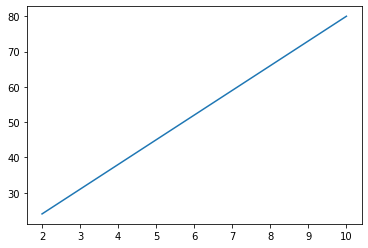

In [8]:
y_obj = theta0_obj + theta1_obj*x_obj;
plt.plot(x_obj, y_obj)

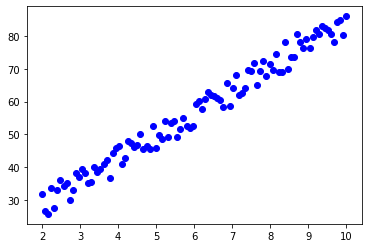

In [5]:
ruido = 10 - 10*np.random.rand(m);
y_obj = theta0_obj + theta1_obj*x_obj;
plt.plot(x_obj, y_obj+(ruido), 'bo')
y_obj = y_obj+(ruido)

**FUNCION DE COSTO**

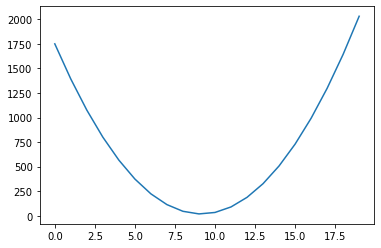

In [6]:
theta0_haz = 0
theta1_haz = np.arange(0, 20)

J = np.zeros(20)
for i in range(20):
    for j in range(m):
        h = theta0_haz + theta1_haz[i]*x_obj[j];
        J[i] = J[i] + (1/(2*m))*(y_obj[j] - h)**2
 
plt.plot(theta1_haz, J)

**ANIMACION**

In [7]:
from matplotlib import animation, rc

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 5))

line1, = ax1.plot([], [], 'o', lw=2)
line2, = ax1.plot([], [], lw=2)
line3, = ax2.plot([], [], lw=2)
line = [line2, line3]

ax1.set_ylim(0, 100)
ax1.set_xlim(0, 10)
ax2.set_ylim(0, 2500)
ax2.set_xlim(0, 20)
plt.close()

def init():
    line1.set_data(x_obj, y_obj)
    return (line1,)    
    
def animate(i):
    x = np.linspace(0, 10, num = 100)
    y = theta1_haz[i]*x  
    line[0].set_data(x, y)
    line[1].set_data(theta1_haz[:i+1], J[:i+1])
    return line

anim = animation.FuncAnimation(fig, animate, init_func=init,
                               frames=20, interval=200, blit=True)

rc('animation', html='jshtml')
anim

**GRADIENTE DESCENDENTE**

10 7
15.074470713771307 6.968105968084145
3.7744270488688274 0.1176835518332024 -0.01709171732814041


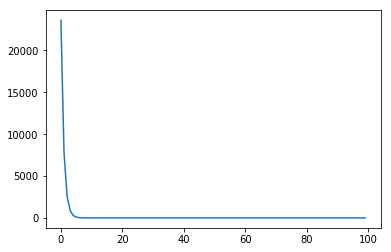

In [ ]:
max_iter = 100
theta0 = 20
theta1 = 40
alpha = 0.01 #Coeficiente de aprendizaje
J = np.zeros(max_iter)
save = [[theta0, theta1]]

for i in range(max_iter):
    dJ0 = 0
    dJ1 = 0
    for j in range(m):
        h = theta0 + theta1*x_obj[j]
        dJ0 = dJ0 + (1/m)*(h - y_obj[j])
        dJ1 = dJ1 + (1/m)*(h - y_obj[j])*x_obj[j]
        J[i]= J[i] + (1/(2*m))*(y_obj[j] - h)**2
    theta0 = theta0 - alpha*dJ0
    theta1 = theta1 - alpha*dJ1
    save.append([theta0, theta1])

print(theta0_obj, theta1_obj)     
print(theta0, theta1)  
print(J[-1], dJ0, dJ1)
plt.plot(range(max_iter), J) 

In [ ]:
save = np.matrix(save)
save.shape[0]
print(save[0,1])

40.0


In [ ]:
from matplotlib import animation, rc

fig, ax = plt.subplots(1, 1, figsize=(10, 5))

line1, = ax.plot([], [], 'o', lw=2)
line2, = ax.plot([], [], lw=2)

ax.set_ylim(0, 300)
ax.set_xlim(0, 20)
plt.close()

def init():
    line1.set_data(x_obj, y_obj)
    return (line1,)    
    
def animate(i):
    x = x_obj
    y = save[i,0] + save[i,1]*x_obj 
    line2.set_data(x, y)
    return line2,

anim = animation.FuncAnimation(fig, animate, init_func=init,
                               frames=save.shape[0], interval=300, blit=True)

rc('animation', html='jshtml')
anim

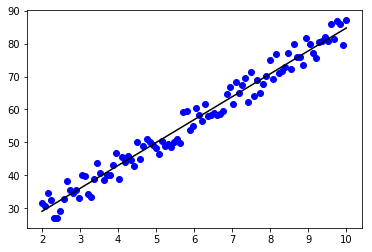

In [ ]:
plt.plot(x_obj, y_obj, 'bo')
plt.plot(x_obj, theta0 + theta1*x_obj, 'k')

**Predicciones**

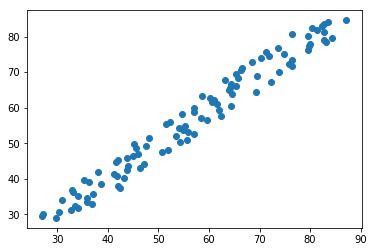

In [ ]:
predicciones = theta0 + theta1*x_obj
plt.scatter(y_obj,predicciones)

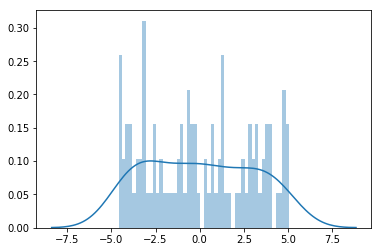

In [ ]:
import seaborn as sns
sns.distplot((y_obj - predicciones),bins=50);

In [ ]:
from sklearn import metrics
print('MAE:', metrics.mean_absolute_error(y_obj,predicciones))
print('MSE:', metrics.mean_squared_error(y_obj,predicciones))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_obj,predicciones)))

MAE: 2.592724765042949
MSE: 8.859955865340865
RMSE: 2.9765677995538526


**OTROS DATOS**

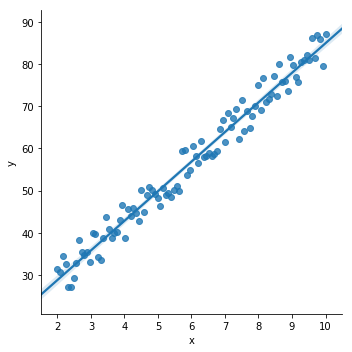

In [ ]:
import pandas as pd
datos = pd.DataFrame( {'x': x_obj, 'y': y_obj} )
g = sns.lmplot(x="x", y="y", data=datos)

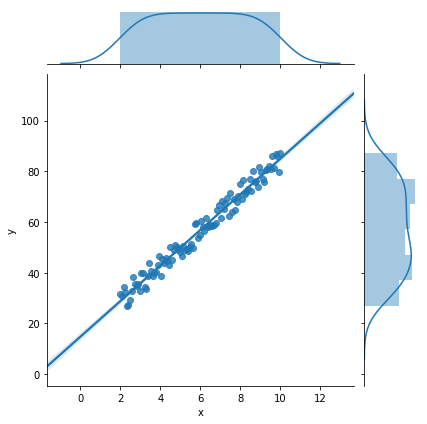

In [ ]:
g = sns.jointplot(x="x", y="y", data=datos, kind = 'reg')

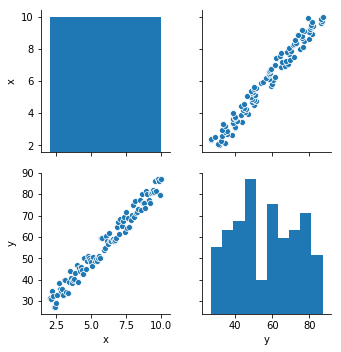

In [ ]:
sns.pairplot(datos)

In [ ]:
sns.heatmap(datos.corr()

,x,y
x,1.000000,0.985709
y,0.985709,1.000000


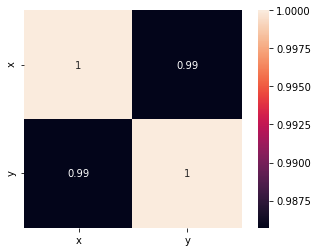

In [ ]:
sns.heatmap(datos.corr(), square=True, annot=True)